# Prototipo: descripción clínica de una fotografía de fondo de ojo

Prototipo del trabajo de graduación sobre *surgical fine-tuning* de MedGemma (`google/medgemma-1.5-4b-it`), con foco en glaucoma. Este cuaderno es el prototipo completo: toda la lógica (carga, inferencia, interfaz y verificación) está en sus celdas, en el orden en que se ejecutan, y cada bloque de código va precedido de lo que hace y por qué.

**Aviso.** No es un sistema clínico. La fidelidad del texto es a los campos (vCDR, hCDR, decisión), no a la imagen.

Con un único modelo en memoria (los adaptadores LoRA se montan una vez y `set_adapter` elige cuál actúa) hay dos caminos:

- **C**: etapa 1 (adaptador de la receta A: imagen → `{vcdr, hcdr, decision}` en JSON) y etapa 2 (LoRA de redacción, que **no ve la imagen**: campos → texto). Con campos de un oftalmólogo se salta la etapa 1.
- **B**: prosa directa; la imagen produce la frase con un adaptador de la receta B.

Dos modos de uso en la interfaz: **(a)** una imagen de la validación de Chákṣu, con la referencia de los expertos tras el resultado; **(b)** una imagen propia sin referencia, con anotaciones opcionales. Orden: definiciones (secciones 1 a 8), carga del modelo (la parte lenta), interfaz y ejemplo con verificación.

## 1. Instrumentos compartidos con los experimentos

El prototipo **no reimplementa** nada de lo que se evaluó: importa los mismos instrumentos del proyecto que usaron los experimentos (`scripts.model.medgemma` carga el modelo y genera; `scripts.model.lora` lee los CSV y arma el prompt de redacción; `scripts.eval.evaluate` y `scripts.eval.fields` leen y validan la respuesta; `scripts.studies.pipeline` define dónde están los adaptadores de cada receta). Así el prototipo muestra exactamente lo que se midió: si una respuesta se considera válida en la evaluación, se considera válida aquí, con el mismo código. Las rutas se resuelven desde la raíz del repositorio, y los datasets viven fuera de él, en `../datasets/`.

In [1]:
import base64
import csv
import html
import io
import json
import math
import sys
import time
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "prototype" else Path.cwd()
assert (REPO / "scripts").is_dir(), f"{REPO} no es la raíz del repositorio"
sys.path.insert(0, str(REPO))

import ipywidgets as widgets
import transformers
from IPython.display import display
from peft import PeftModel
from safetensors import safe_open
from PIL import Image, ImageOps

from scripts.eval.evaluate import DECISIONS, NUMERIC, is_number, parse_answer
from scripts.eval.fields import extract_prose
from scripts.model.lora import fill_prompt, read_csv
from scripts.model.medgemma import generate, load_medgemma

DATASETS_ROOT = REPO.parent / "datasets"
MAX_NEW_TOKENS = 128          # tope de tokens generados por llamada (el de los experimentos)
UPLOAD_EXTENSIONS = (".jpg", ".jpeg", ".png", ".tif", ".tiff")
UPLOAD_MAX_BYTES = 50 * 1024 * 1024

## 2. Qué adaptadores se ofrecen

Cada opción del selector es un adaptador del estudio con su celda de la rejilla. Criterio: la celda de menor error del vCDR en el Test (`all-linear`) y las dos siguientes entre las finalistas que no son controles aleatorios (`block_language`, `mlp_language`), más la prosa directa de la receta B como opción de formato. `path` dice por cuál camino va cada opción (C o B). `PROMPT_RECIPES` asocia cada prompt con la receta cuyo archivo de targets lo guarda, y `DISCLAIMER` es el aviso que la interfaz muestra siempre.

In [2]:
# Opciones del selector. Cada una es un adaptador del estudio con su celda de la rejilla. Criterio (ver prototype/README.md):
# la celda de menor error del vCDR en el Test (all-linear) y las dos siguientes entre las celdas finalistas que no son
# controles aleatorios (block_language, mlp_language), más la prosa directa de la receta B como opción de formato.
OPTIONS = {
    "A_all_linear": {"folder": "A_all-linear", "label": "A · all-linear (menor error del vCDR en el Test)", "recipe": "json_v1", "cell": "all-linear", "path": "C"},
    "A_block_language": {"folder": "A_block_language", "label": "A · block_language (2.º mejor finalista del Test)", "recipe": "json_v1", "cell": "block_language", "path": "C"},
    "A_mlp_language": {"folder": "A_mlp_language", "label": "A · mlp_language (3.º mejor finalista del Test)", "recipe": "json_v1", "cell": "mlp_language", "path": "C"},
    "B_all_linear": {"folder": "B_all-linear", "label": "B · prosa directa, all-linear (formato de una frase desde la imagen)", "recipe": "prose_v1", "cell": "all-linear", "path": "B"},
}
STAGE2_NAME = "verbalize"
STAGE2_FOLDER = "redaccion_block_language"
ADAPTERS = REPO / "adapters"
PROMPT_RECIPES = {"A": "json_v1", "B": "prose_v1", STAGE2_NAME: "verbalize_v1"}
DISCLAIMER = ("No es un sistema clínico ni un dispositivo médico: está entrenado con una sola base de datos (Chákṣu) y no está validado "
              "para apoyar una decisión sobre un paciente. En el camino C la redacción describe los <b>campos</b> (vCDR, hCDR, decisión), "
              "no la imagen: un texto fiel a campos equivocados es un texto equivocado y fluido.")

## 3. Ubicación y ficha de cada adaptador

Los adaptadores se leen de `adapters/<carpeta>/` (semilla de entrenamiento 42; los adaptadores no se incluyen en el repositorio por su tamaño y se piden al autor). `adapter_dir` y `stage2_dir` devuelven la carpeta y comprueban con un `assert` que existen los dos archivos. `adapter_card` y `stage2_card` arman la ficha que muestra la interfaz: los parámetros entrenables se cuentan sumando el tamaño de los tensores del archivo de pesos y el error del vCDR (media y desviación de tres semillas) se **lee** de las tablas de la rejilla; ninguna cifra está escrita a mano. Un `assert` falla con un mensaje claro si la celda no aparece exactamente una vez.


In [3]:
def adapter_path(folder):
    path = ADAPTERS / folder
    for name in ("adapter_model.safetensors", "adapter_config.json"):
        assert (path / name).is_file(), (f"falta {path / name}: los adaptadores no se incluyen en el repositorio por su tamaño; "
                                         "se entregan por solicitud al autor y se colocan en adapters/")
    return path


def adapter_dir(option):
    return adapter_path(OPTIONS[option]["folder"])


def stage2_dir():
    return adapter_path(STAGE2_FOLDER)


def trainable_params(path):
    """Parámetros entrenables de un LoRA: suma de los elementos de todos los tensores del archivo de pesos."""
    with safe_open(path / "adapter_model.safetensors", framework="pt") as weights:
        return sum(math.prod(weights.get_slice(name).get_shape()) for name in weights.keys())


def adapter_card(option):
    """Ubicación, parámetros entrenables y error del vCDR (media y desviación de tres semillas) en validación y Test,
    leídos del archivo de pesos y de las tablas de la rejilla."""
    spec = OPTIONS[option]
    folder = REPO / "results" / "grids" / f"chaksu_{spec['recipe']}"

    def row(name):
        rows = [r for r in read_csv(folder / name) if r["cell"] == spec["cell"]]
        assert len(rows) == 1, f"{folder / name}: la celda {spec['cell']} aparece {len(rows)} veces"
        return rows[0]

    validation, test = row("results.csv"), row("results_test.csv")
    path = adapter_dir(option)
    return {"option": option, "label": spec["label"], "path": path.relative_to(REPO), "trainable": trainable_params(path),
            "validation": f"{float(validation['vcdr_error_mean']):.4f} ± {float(validation['vcdr_error_sd']):.4f}",
            "test": f"{float(test['vcdr_error_mean']):.4f} ± {float(test['vcdr_error_sd']):.4f}"}


def stage2_card():
    path = stage2_dir()
    return {"label": "Etapa 2 · LoRA de redacción block_language (campos → texto; sin imagen)", "path": path.relative_to(REPO),
            "trainable": trainable_params(path)}


## 4. Carga del modelo y de los adaptadores, una sola vez

`load_prototype` carga MedGemma en bf16 una sola vez y le monta los cinco adaptadores con nombre (cuatro de medición y el de redacción); después basta `set_adapter` para elegir cuál actúa, sin recargar pesos. También lee los prompts de entrenamiento y la partición de validación de Chákṣu (imagen y referencia de cada fila). Se silencian los avisos informativos y las barras de carga de la librería, que no son resultados, y se fija una vez el `pad_token_id` que `generate` avisaría en cada llamada (con una sola secuencia por llamada no hay relleno, así que no altera la salida). Al final se comprueba que los nombres montados son exactamente los esperados.

In [4]:
@dataclass
class Prototype:
    processor: object
    model: object
    prompts: dict
    cards: dict
    stage2: dict
    validation: list        # filas de la partición validation de Chákṣu (targets de la receta de prosa): imagen y referencia


def load_prototype():
    """Carga MedGemma una vez en bf16 y monta todos los adaptadores con nombre. Cada nombre se comprueba contra `set_adapter`."""
    cards = {option: adapter_card(option) for option in OPTIONS}
    stage2 = stage2_card()
    prompts = {name: (REPO / "data" / "targets" / f"chaksu__{recipe}.prompt.txt").read_text(encoding="utf-8").strip()
               for name, recipe in PROMPT_RECIPES.items()}
    split_of = {r["image_id"]: r["split"] for r in read_csv(REPO / "data" / "splits" / "chaksu_seed42.csv")}
    validation = [r for r in read_csv(REPO / "data" / "targets" / "chaksu__prose_v1.csv") if split_of[r["image_id"]] == "validation"]
    assert validation, "la partición validation está vacía"

    # Ruido de la librería, no de los resultados: avisos informativos (procesador de imagen lento, etc.) y barras de carga.
    transformers.utils.logging.set_verbosity_error()
    transformers.utils.logging.disable_progress_bar()
    processor, model = load_medgemma()
    # `generate` sin pad_token_id lo toma del eos y avisa en cada llamada; se fija el mismo valor una vez. Con una sola
    # secuencia por llamada no hay relleno, así que el valor no altera la salida.
    eos = model.generation_config.eos_token_id
    model.generation_config.pad_token_id = eos[0] if isinstance(eos, list) else eos
    options = list(OPTIONS)
    model = PeftModel.from_pretrained(model, adapter_dir(options[0]), adapter_name=options[0])
    for option in options[1:]:
        model.load_adapter(adapter_dir(option), adapter_name=option)
    model.load_adapter(stage2_dir(), adapter_name=STAGE2_NAME)
    model.eval()
    assert set(model.peft_config) == set(OPTIONS) | {STAGE2_NAME}, sorted(model.peft_config)
    return Prototype(processor, model, prompts, cards, stage2, validation)

## 5. Elegir y activar el adaptador, y comprobar que es el pedido

`run` hace una generación voraz (determinista). Con `adapter=None` desactiva los adaptadores y corre el modelo base. Si no, llama a `set_adapter` y **comprueba con un `assert`** que `active_adapters` es el pedido: `set_adapter` no falla si el nombre existe pero no cambia nada si se llama sobre el modelo equivocado, un fallo silencioso que de otro modo daría salidas de un adaptador distinto del que se cree.

In [5]:
def run(proto, adapter, prompt, image=None):
    """Una generación voraz (determinista). `adapter` es el nombre de un adaptador o None para el modelo base.
    Antes de generar se comprueba que el adaptador activo es el pedido: `set_adapter` no falla si el nombre existe pero
    no cambia nada si se llama sobre el modelo equivocado."""
    model = proto.model
    if adapter is None:
        with model.disable_adapter():
            return generate(proto.processor, model, prompt, image, MAX_NEW_TOKENS).strip()
    model.set_adapter(adapter)
    assert model.active_adapters == [adapter], f"adaptador activo {model.active_adapters}, se pidió {adapter}"
    return generate(proto.processor, model, prompt, image, MAX_NEW_TOKENS).strip()

## 6. Lectura y validación de los campos

`read_fields` lee la respuesta JSON de la etapa 1 con el mismo lector de la evaluación (`parse_answer`) y devuelve los tres campos solo si son válidos (vCDR y hCDR numéricos y una decisión conocida); si no, devuelve `None` y no se inventa nada. `check_fields` valida las anotaciones de un oftalmólogo antes de redactarlas: los tres campos, los cocientes entre 0 y 1 y una decisión permitida.

In [6]:
def read_fields(raw):
    """Los tres campos de la respuesta JSON de la etapa 1 (el lector de la evaluación); None si no hay los tres válidos."""
    answer = parse_answer(raw)
    if answer is None:
        return None
    fields = {k: answer.get(k) for k in ("vcdr", "hcdr", "decision")}
    if not all(is_number(fields[k]) for k in NUMERIC) or fields["decision"] not in DECISIONS:
        return None
    return fields


def check_fields(fields, what):
    assert set(fields) == {"vcdr", "hcdr", "decision"}, f"{what}: hacen falta vcdr, hcdr y decision"
    assert all(0.0 <= float(fields[k]) <= 1.0 for k in NUMERIC), f"{what}: vcdr y hcdr van entre 0 y 1"
    assert fields["decision"] in DECISIONS, f"{what}: la decisión es una de {DECISIONS}"

## 7. Los dos caminos: etapas e inferencia

`_path` ejecuta un camino. En **B** la imagen produce directamente la frase. En **C** la etapa 1 lee la imagen y da los campos (o se usan las anotaciones del oftalmólogo, que saltan la etapa 1), y la etapa 2 redacta el texto solo con los campos. Con el modelo base (`adapter_of=None`) se usa también el base para redactar. Se mide el tiempo de cada etapa. `infer` es la función pública: recibe una imagen, una opción y, si se quiere, anotaciones, y con `compare_base` repite el mismo camino con el modelo sin adaptar. No depende de la interfaz.

In [7]:
def _path(proto, adapter_of, route, image, annotations):
    """`adapter_of`: nombre del adaptador de la etapa de imagen (None = base); `route`: "C" o "B"."""
    seconds = {}
    if route == "B":
        assert annotations is None, "la prosa directa (B) no usa anotaciones: parte de la imagen"
        tic = time.time()
        text = run(proto, adapter_of, proto.prompts["B"], image)
        seconds["imagen → texto"] = time.time() - tic
        return {"fields": extract_prose(text), "raw_stage1": None, "text": text, "seconds": seconds, "source": "imagen"}
    stage2_adapter = None if adapter_of is None else STAGE2_NAME
    if annotations is not None:
        check_fields(annotations, "anotaciones")
        fields, raw, source = dict(annotations), None, "anotaciones del oftalmólogo"
    else:
        tic = time.time()
        raw = run(proto, adapter_of, proto.prompts["A"], image)
        seconds["etapa 1 (imagen → campos)"] = time.time() - tic
        fields, source = read_fields(raw), "imagen"
        if fields is None:
            return {"fields": None, "raw_stage1": raw, "text": None, "seconds": seconds, "source": source}
    tic = time.time()
    text = run(proto, stage2_adapter, fill_prompt(proto.prompts[STAGE2_NAME], fields["vcdr"], fields["hcdr"], fields["decision"]))
    seconds["etapa 2 (campos → texto)"] = time.time() - tic
    return {"fields": fields, "raw_stage1": raw, "text": text, "seconds": seconds, "source": source}


def infer(proto, image, option, annotations=None, compare_base=False):
    """Descripción de una imagen PIL RGB con la opción de adaptador `option` (clave de OPTIONS).

    `annotations`: None (los campos salen de la imagen) o {"vcdr", "hcdr", "decision"} de un oftalmólogo (se redactan con la
    etapa 2 sin pasar por la imagen). Con `compare_base` se repite el mismo camino con el modelo sin adaptar.
    Devuelve {"adapter": resultado, "base": resultado o None}; cada resultado trae `fields`, `text`, `raw_stage1`,
    `seconds` (por etapa) y `source`.
    """
    route = OPTIONS[option]["path"]
    result = {"adapter": _path(proto, option, route, image, annotations), "base": None}
    if compare_base:
        result["base"] = _path(proto, None, route, image, annotations)
    return result

## 8. Error frente a la referencia y presentación en texto

`reference_error` calcula el error absoluto del vCDR y del hCDR y si la decisión coincide con la referencia, y devuelve `None` donde los campos no se leyeron. `describe` presenta un resultado en texto plano (campos, texto, tiempos y, si hay referencia, el error). `decode_image` convierte los bytes de un archivo subido en una imagen RGB aplicando la orientación EXIF, con límites de formato y tamaño. Recuerda: la concordancia con la anotación no es fidelidad a la imagen.

In [8]:
def reference_error(fields, reference):
    """Error absoluto del vCDR y del hCDR, y acierto de la decisión, de unos campos frente a una referencia
    ({vcdr, hcdr, decision}); None donde los campos no se leyeron."""
    if fields is None:
        return {"vcdr": None, "hcdr": None, "decision": None}
    out = {k: None if fields[k] is None else abs(float(fields[k]) - float(reference[k])) for k in NUMERIC}
    out["decision"] = None if fields["decision"] is None else fields["decision"] == reference["decision"]
    return out


def describe(result, reference=None):
    """Un resultado en texto plano: campos, texto, tiempo y, si hay referencia ({vcdr, hcdr, decision}), el error del vCDR."""
    fields = result["fields"]
    if fields is None:
        return f"campos no legibles; salida cruda: {result['raw_stage1']!r}"
    shown = " · ".join("%s %s" % (k, "no legible" if v is None else f"{float(v):.2f}" if k in NUMERIC else v) for k, v in fields.items())
    lines = [f"campos (desde {result['source']}): {shown}"]
    if result["text"]:
        lines.append(f"texto: {result['text']}")
    lines.append("tiempo: " + (", ".join(f"{k} {v:.1f} s" for k, v in result["seconds"].items()) or "sin generación") +
                 f" (total {sum(result['seconds'].values()):.1f} s)")
    if reference:
        error = reference_error(fields, reference)
        lines.append(f"referencia: vCDR {float(reference['vcdr']):.2f} · hCDR {float(reference['hcdr']):.2f} · {reference['decision']}; "
                     f"error del vCDR {number_html(error['vcdr'], 3)}, decisión {'coincide' if error['decision'] else 'no coincide'}")
    return "\n".join(lines)


def decode_image(name, content):
    """Imagen RGB desde los bytes de un archivo subido (la orientación EXIF se aplica; de un TIFF se toma la primera página)."""
    assert name.lower().endswith(UPLOAD_EXTENSIONS), f"{name}: formato no admitido, usa {', '.join(UPLOAD_EXTENSIONS)}"
    assert len(content) <= UPLOAD_MAX_BYTES, f"{name}: más de {UPLOAD_MAX_BYTES // 2**20} MB"
    return ImageOps.exif_transpose(Image.open(io.BytesIO(content))).convert("RGB")


def number_html(value, digits=2):
    return "no legible" if value is None else f"{float(value):.{digits}f}"

## 9. Presentación en HTML

Estilos y funciones que convierten imágenes, resultados y fichas en HTML para la interfaz: miniatura de la imagen, tabla de campos con el error frente a la referencia cuando existe, y la ficha de cada adaptador. Todo texto que viene de datos o del modelo se escapa (`esc`) antes de insertarse.

In [9]:
CSS = """<style>
.pt{font-family:var(--jp-ui-font-family,sans-serif);color:var(--jp-ui-font-color1,inherit);line-height:1.45}
.pt .box{border:1px solid rgba(128,128,128,.4);border-radius:8px;padding:10px 14px;margin:6px 0}
.pt .warn{border-left:5px solid #e0a000;background:rgba(224,160,0,.14);border-radius:6px;padding:8px 12px}
.pt .ok{border-left:5px solid #2e9b57;background:rgba(46,155,87,.10);border-radius:6px;padding:8px 12px}
.pt .text{font-size:1.05em;border-left:4px solid #3b7dd8;padding:4px 12px;margin:6px 0}
.pt table{border-collapse:collapse;margin:6px 0}
.pt td,.pt th{border:1px solid rgba(128,128,128,.4);padding:4px 10px;text-align:left}
.pt .small{font-size:.9em;opacity:.85}
.pt code{font-size:.9em}
</style>"""


def esc(value):
    return html.escape(str(value))


def image_html(image, size=360):
    thumb = image.copy()
    thumb.thumbnail((size, size))
    buffer = io.BytesIO()
    thumb.save(buffer, format="JPEG", quality=90)
    return f"<img src='data:image/jpeg;base64,{base64.b64encode(buffer.getvalue()).decode()}' style='max-width:100%;border-radius:6px'>"


def result_html(title, result, reference=None, reference_label=""):
    """Un resultado (campos, texto, tiempos) y, si hay referencia, el error frente a ella."""
    if result["fields"] is None:
        return (f"<div class='box'><b>{esc(title)}</b><div class='warn'>La etapa 1 no dio los tres campos legibles; no hay etapa 2. "
                f"Salida cruda: <code>{esc(result['raw_stage1'])}</code></div></div>")
    fields = result["fields"]
    errors = reference_error(fields, reference) if reference else None
    head = "<tr><th>Campo</th><th>Valor medido</th>" + (f"<th>{esc(reference_label)}</th><th>Error</th>" if reference else "") + "</tr>"
    rows = ""
    for key, name in (("vcdr", "vCDR"), ("hcdr", "hCDR"), ("decision", "Decisión")):
        value = fields[key]
        cell = number_html(value) if key in NUMERIC else ("no legible" if value is None else esc(value))
        extra = ""
        if reference:
            ref = f"{float(reference[key]):.2f}" if key in NUMERIC else esc(reference[key])
            err = errors[key]
            shown = "—" if err is None else (f"{err:.3f}" if key in NUMERIC else ("coincide" if err else "no coincide"))
            extra = f"<td>{ref}</td><td>{shown}</td>"
        rows += f"<tr><td>{name}</td><td>{cell}</td>{extra}</tr>"
    seconds = ", ".join(f"{k}: {v:.1f} s" for k, v in result["seconds"].items()) or "sin generación (campos dados)"
    text = f"<div class='text'>{esc(result['text'])}</div>" if result["text"] else ""
    return (f"<div class='box'><b>{esc(title)}</b> <span class='small'>(campos desde: {esc(result['source'])})</span>{text}"
            f"<table>{head}{rows}</table><div class='small'>Tiempo: {esc(seconds)} · total {sum(result['seconds'].values()):.1f} s</div></div>")


def card_html(card):
    return (f"<div class='box'><b>{esc(card['label'])}</b><br>Ubicación: <code>{esc(card['path'])}</code><br>"
            f"Parámetros entrenables: {card['trainable']:,}".replace(",", " ") +
            (f"<br>Error del vCDR (media ± desviación de 3 semillas): Test {card['test']} · validación {card['validation']}"
             if "test" in card else "<br>No mide el vCDR: redacta el texto a partir de los campos") + "</div>")

## 10. La interfaz con los dos modos

`Interface` construye la interfaz de ipywidgets. `root` es el widget a mostrar; `run_reference` (modo a: imagen de validación con su referencia) y `run_own` (modo b: imagen subida, sin referencia, con anotaciones y referencia propia opcionales) son lo que hacen los botones, así que se pueden llamar desde código sin navegador. El selector de adaptador se aplica a los dos modos, y los errores de un clic quedan visibles en pantalla en lugar de perderse.

In [10]:
class Interface:
    """La interfaz de ipywidgets. `root` es el widget a mostrar; `run_reference` y `run_own` son lo que hacen los botones
    (se pueden llamar sin navegador y devuelven el resultado de `infer`)."""

    def __init__(self, proto):
        self.proto = proto
        self.validation = {r["image_id"]: r for r in proto.validation}
        self.examples = self._examples()
        wide = widgets.Layout(width="100%")
        style = {"description_width": "170px"}

        self.option = widgets.Dropdown(options=[(spec["label"], key) for key, spec in OPTIONS.items()], description="Adaptador",
                                       layout=wide, style=style)
        self.compare_base = widgets.Checkbox(value=True, description="Mostrar también el modelo base sin adaptar", indent=False)
        self.card = widgets.HTML()
        self.option.observe(lambda change: self._show_card(), names="value")
        self._show_card()

        # Modo (a): una imagen de la validación de Chákṣu, con su referencia.
        self.example = widgets.ToggleButtons(options=[(label, image_id) for image_id, label in self.examples], value=None,
                                             description="Ejemplos", style={"button_width": "190px", "description_width": "70px"})
        self.camera = widgets.Dropdown(options=sorted({r["camera"] for r in proto.validation}), description="Cámara", style=style)
        self.image_id = widgets.Dropdown(description="Imagen de validación", layout=wide, style=style)
        self.preview_ref = widgets.HTML()
        self.run_ref = widgets.Button(description="Medir y redactar", button_style="primary", icon="play", layout=widgets.Layout(width="220px"))
        self.out_ref = widgets.HTML()
        self.err_ref = widgets.Output()
        self.camera.observe(lambda change: self._fill_images(), names="value")
        self.image_id.observe(lambda change: self._preview_reference(), names="value")
        self.example.observe(self._pick_example, names="value")
        self.run_ref.on_click(self._click(self.run_reference, self.run_ref, self.out_ref, self.err_ref))
        self._fill_images()

        # Modo (b): una imagen propia, sin referencia.
        self.upload = widgets.FileUpload(accept=",".join(UPLOAD_EXTENSIONS), multiple=False, description="Elegir imagen…",
                                         icon="upload", layout=widgets.Layout(width="260px", height="70px"))
        self.preview_own = widgets.HTML("<div class='pt small'>Ninguna imagen subida todavía.</div>")
        self.use_annotations = widgets.Checkbox(value=False, description="Tengo las anotaciones de un oftalmólogo (se redactan sin pasar por la imagen)", indent=False)
        self.ann = self._field_widgets()
        self.use_reference = widgets.Checkbox(value=False, description="Tengo una referencia propia para comparar el resultado", indent=False)
        self.ref = self._field_widgets()
        self.run_own_button = widgets.Button(description="Medir y redactar", button_style="primary", icon="play", layout=widgets.Layout(width="220px"))
        self.out_own = widgets.HTML()
        self.err_own = widgets.Output()
        self.upload.observe(lambda change: self._preview_upload(), names="value")
        for box, flag in ((self.ann, self.use_annotations), (self.ref, self.use_reference)):
            flag.observe(lambda change, box=box: setattr(box, "layout", widgets.Layout(display="flex" if change["new"] else "none")), names="value")
        self.run_own_button.on_click(self._click(self.run_own, self.run_own_button, self.out_own, self.err_own))

        self.root = self._layout()

    # --- construcción -------------------------------------------------------------------------------------------

    def _examples(self):
        """Seis ejemplos de la validación: por cada cámara, la primera imagen (por id) normal y la primera sospechosa."""
        chosen = []
        for camera in sorted({r["camera"] for r in self.proto.validation}):
            for decision, name in (("NORMAL", "normal"), ("GLAUCOMA SUSPECT", "sospechoso")):
                rows = sorted((r for r in self.proto.validation if r["camera"] == camera and r["decision"] == decision), key=lambda r: r["image_id"])
                assert rows, f"no hay imagen {name} de {camera} en la validación"
                chosen.append((rows[0]["image_id"], f"{camera} · {name}"))
        assert len(chosen) == 6
        return chosen

    @staticmethod
    def _field_widgets():
        vcdr = widgets.BoundedFloatText(value=0.5, min=0.0, max=1.0, step=0.01, description="vCDR", layout=widgets.Layout(width="200px"))
        hcdr = widgets.BoundedFloatText(value=0.5, min=0.0, max=1.0, step=0.01, description="hCDR", layout=widgets.Layout(width="200px"))
        decision = widgets.Dropdown(options=list(DECISIONS), description="Decisión", layout=widgets.Layout(width="300px"))
        box = widgets.HBox([vcdr, hcdr, decision], layout=widgets.Layout(display="none"))
        box.vcdr, box.hcdr, box.decision = vcdr, hcdr, decision
        return box

    @staticmethod
    def _values(box):
        return {"vcdr": box.vcdr.value, "hcdr": box.hcdr.value, "decision": box.decision.value}

    def _layout(self):
        def html_box(content):
            return widgets.HTML(f"<div class='pt'>{content}</div>")

        banner = widgets.HTML(f"{CSS}<div class='pt'><div class='warn'><b>Aviso.</b> {DISCLAIMER}</div></div>")
        selector = widgets.VBox([html_box("<b>1. Elige el adaptador</b> <span class='small'>(se aplica a las dos pestañas de imagen)</span>"),
                                 self.option, self.card, self.compare_base])
        mode_a = widgets.VBox([
            html_box("<b>Modo (a): imagen con referencia conocida.</b> Imágenes de la partición de <i>validación</i> de Chákṣu. "
                     "Tras el resultado se muestra lo que dijeron los expertos y el error del vCDR."),
            self.example, widgets.HBox([self.camera]), self.image_id, self.preview_ref, self.run_ref, self.err_ref, self.out_ref])
        mode_b = widgets.VBox([
            html_box("<b>Modo (b): imagen propia, sin referencia.</b> Sube cualquier fotografía de fondo de ojo (JPG, PNG o TIFF). "
                     "El resultado no muestra ninguna referencia."),
            self.upload, html_box("<span class='small'>Se elige con el botón. Arrastrar y soltar sobre el botón depende del navegador y de la versión de "
                                  "JupyterLab; si no responde, usa el botón.</span>"),
            self.preview_own, self.use_annotations, self.ann, self.use_reference, self.ref, self.run_own_button, self.err_own, self.out_own])
        adapters = widgets.VBox([html_box("<b>Adaptadores que ofrece el prototipo</b> (semilla de entrenamiento 42). Error del vCDR: media ± desviación de tres "
                                          "semillas en validación (171 imágenes) y Test (reservado).")]
                                + [html_box(card_html(c)) for c in self.proto.cards.values()] + [html_box(card_html(self.proto.stage2))])
        limits = html_box("<b>Qué no es.</b><ul>"
                          "<li>No es un sistema clínico ni un dispositivo médico; toda salida debe revisarla un oftalmólogo.</li>"
                          "<li>La fidelidad del texto es a los campos, no a la imagen. La etapa 2 no ve la imagen.</li>"
                          "<li>Una sola imagen no demuestra nada: los errores publicados son medias sobre decenas de imágenes y semillas.</li>"
                          "<li>Entrenado con Chákṣu (cámaras Bosch, Forus y Remidio, cinco expertos); la decisión es «normal» frente a «sospechoso». "
                          "Fuera de ese dominio (otras cámaras, poblaciones o fotografías no centradas en el disco) no hay garantía.</li>"
                          "<li>En imagen propia sin referencia no se puede decir si el resultado es correcto.</li></ul>")
        tabs = widgets.Tab(children=[mode_a, mode_b, adapters, limits])
        for index, title in enumerate(("Imagen con referencia conocida", "Imagen propia, sin referencia", "Adaptadores", "Límites")):
            tabs.set_title(index, title)
        return widgets.VBox([banner, selector, html_box("<b>2. Elige el modo</b>"), tabs], layout=widgets.Layout(width="100%", max_width="980px"))

    # --- comportamiento -----------------------------------------------------------------------------------------

    def _show_card(self):
        self.card.value = f"<div class='pt'>{card_html(self.proto.cards[self.option.value])}</div>"

    def _fill_images(self):
        rows = sorted((r for r in self.proto.validation if r["camera"] == self.camera.value), key=lambda r: r["image_id"])
        self.image_id.options = [(f"{r['image_id']} · {r['decision'].lower()}", r["image_id"]) for r in rows]

    def _pick_example(self, change):
        if change["new"] is None:
            return
        self.camera.value = self.validation[change["new"]]["camera"]
        self.image_id.value = change["new"]

    def _reference_image(self):
        row = self.validation[self.image_id.value]
        return row, Image.open(DATASETS_ROOT / row["image"]).convert("RGB")

    def _preview_reference(self):
        if self.image_id.value is None:
            return
        row, image = self._reference_image()
        self.preview_ref.value = f"<div class='pt'>{image_html(image)}<div class='small'>{esc(row['image_id'])} · {esc(row['camera'])}</div></div>"

    def _uploaded(self):
        assert len(self.upload.value) == 1, "sube una imagen primero"
        item = self.upload.value[0]
        return item["name"], decode_image(item["name"], bytes(item["content"]))

    def _preview_upload(self):
        if not self.upload.value:
            return
        name, image = self._uploaded()
        self.preview_own.value = f"<div class='pt'>{image_html(image)}<div class='small'>{esc(name)} · {image.width}×{image.height} px</div></div>"

    @staticmethod
    def _click(action, button, out, err):
        """Botón: ejecuta `action`, deshabilita el botón mientras corre y deja cualquier error visible en `err`."""
        @err.capture(clear_output=True)
        def handler(_):
            button.disabled = True
            out.value = "<div class='pt'>Procesando…</div>"
            try:
                action()
            finally:
                button.disabled = False
        return handler

    def run_reference(self):
        row, image = self._reference_image()
        result = infer(self.proto, image, self.option.value, compare_base=self.compare_base.value)
        reference = {k: row[k] for k in ("vcdr", "hcdr", "decision")}
        spec = OPTIONS[self.option.value]
        parts = [f"<div class='pt'>{image_html(image)}", result_html(spec["label"], result["adapter"], reference, "Referencia de los expertos")]
        if result["base"]:
            parts.append(result_html("Modelo base, sin adaptar", result["base"], reference, "Referencia de los expertos"))
        parts.append(f"<div class='box ok'><b>Referencia de los expertos (Chákṣu, {esc(row['camera'])})</b>: vCDR {float(row['vcdr']):.2f}, "
                     f"hCDR {float(row['hcdr']):.2f}, {esc(row['decision'])}<div class='text'>{esc(row['text'])}</div></div></div>")
        self.out_ref.value = "".join(parts)
        return result

    def run_own(self):
        name, image = self._uploaded()
        annotations = self._values(self.ann) if self.use_annotations.value else None
        reference = self._values(self.ref) if self.use_reference.value else None
        result = infer(self.proto, image, self.option.value, annotations, self.compare_base.value)
        spec = OPTIONS[self.option.value]
        label = "Referencia propia" if reference else ""
        parts = [f"<div class='pt'>{image_html(image)}", result_html(spec["label"], result["adapter"], reference, label)]
        if result["base"]:
            parts.append(result_html("Modelo base, sin adaptar", result["base"], reference, label))
        parts.append("<div class='small'>Sin referencia no se puede decir si el resultado es correcto.</div>" if not reference else
                     "<div class='small'>La comparación es con la referencia que escribiste, no con la de los expertos de Chákṣu.</div>")
        self.out_own.value = "".join(parts) + "</div>"
        return result

## 11. Carga

Se ejecuta la carga de la sección 4: es la celda más lenta (unos minutos). Los adaptadores montados son los de la semilla de entrenamiento 42.


In [11]:
proto = load_prototype()
print(f"MedGemma cargado con {len(proto.model.peft_config)} adaptadores (semilla 42): {', '.join(sorted(proto.model.peft_config))}")

MedGemma cargado con 5 adaptadores (semilla 42): A_all_linear, A_block_language, A_mlp_language, B_all_linear, verbalize


## 12. Interfaz

Selector de adaptador con sus cifras, los dos modos y el aviso de no uso clínico. Se guarda el cuaderno sin el estado de los widgets (por eso la interfaz se ve al ejecutarlo, no en el archivo).

In [12]:
ui = Interface(proto)
display(ui.root)

## 13. Ejemplo y verificación

La misma ruta que los botones, llamada desde código, con imágenes de la validación de Chákṣu: (a) con referencia; (b) una imagen «subida» como archivo, sin referencia; y un recorrido del selector que comprueba que cada opción activa su adaptador y que las salidas difieren.

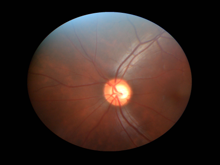

Modo (a) · Chákṣu validación bosch_Image154 · A · all-linear (menor error del vCDR en el Test)
campos (desde imagen): vcdr 0.56 · hcdr 0.64 · decision NORMAL
texto: Optic nerve head: vertical CDR 0.56, horizontal CDR 0.64, optic disc classified as normal.
tiempo: etapa 1 (imagen → campos) 15.2 s, etapa 2 (campos → texto) 1.9 s (total 17.1 s)
referencia: vCDR 0.61 · hCDR 0.67 · GLAUCOMA SUSPECT; error del vCDR 0.048, decisión no coincide

Modelo base, sin adaptar:
campos (desde imagen): vcdr 0.50 · hcdr 0.50 · decision NORMAL
texto: The optic nerve head was classified as normal based on the automated analysis. The vertical cup-to-disc ratio measured 0.50 and the horizontal cup-to-disc ratio measured 0.50.
tiempo: etapa 1 (imagen → campos) 1.6 s, etapa 2 (campos → texto) 1.0 s (total 2.6 s)
referencia: vCDR 0.61 · hCDR 0.67 · GLAUCOMA SUSPECT; error del vCDR 0.108, decisión no coincide



Modo (b) · imagen subida 82.png, sin referencia
campos (desde imagen): vcdr 0.64 · hcdr 0.64 · decision GLAUCOMA SUSPECT
texto: Fundus photograph, optic nerve head: vertical CDR 0.64, horizontal CDR 0.64, optic disc classified as glaucoma suspect.
tiempo: etapa 1 (imagen → campos) 1.2 s, etapa 2 (campos → texto) 1.1 s (total 2.2 s)



Modo (b) con anotaciones
campos (desde anotaciones del oftalmólogo): vcdr 0.60 · hcdr 0.58 · decision GLAUCOMA SUSPECT
texto: Fundus photograph, optic nerve head: vertical CDR 0.60, horizontal CDR 0.58, glaucoma suspect.
tiempo: etapa 2 (campos → texto) 0.9 s (total 0.9 s)

Selector de adaptadores sobre la imagen subida:


  A_all_linear      campos (desde imagen): vcdr 0.64 · hcdr 0.64 · decision GLAUCOMA SUSPECT


  A_block_language  campos (desde imagen): vcdr 0.65 · hcdr 0.65 · decision GLAUCOMA SUSPECT


  A_mlp_language    campos (desde imagen): vcdr 0.65 · hcdr 0.63 · decision GLAUCOMA SUSPECT


  B_all_linear      campos (desde imagen): vcdr 0.62 · hcdr 0.65 · decision GLAUCOMA SUSPECT
Selector verificado.


In [13]:
ids = dict((label, image_id) for image_id, label in ui.examples)

# Modo (a): imagen con referencia conocida.
ui.option.value = "A_all_linear"
ui.example.value = ids["Bosch · sospechoso"]
assert ui.image_id.value == ids["Bosch · sospechoso"]
row, image = ui._reference_image()
reference = {k: row[k] for k in ("vcdr", "hcdr", "decision")}
result = ui.run_reference()
assert "Referencia de los expertos" in ui.out_ref.value
thumb = image.copy()
thumb.thumbnail((220, 220))
display(thumb)
print(f"Modo (a) · Chákṣu validación {row['image_id']} · {OPTIONS[ui.option.value]['label']}")
print(describe(result["adapter"], reference))
print("\nModelo base, sin adaptar:")
print(describe(result["base"], reference))

# Modo (b): imagen propia sin referencia. Se sube como archivo y el resultado no contiene referencia.
path = REPO.parent / "datasets" / ui.validation[ids["Forus · sospechoso"]]["image"]
ui.upload.value = ({"name": path.name, "type": "image/png", "size": path.stat().st_size,
                   "last_modified": datetime.fromtimestamp(path.stat().st_mtime), "content": path.read_bytes()},)
result = ui.run_own()
assert "Referencia" not in ui.out_own.value and "expertos" not in ui.out_own.value
print(f"\nModo (b) · imagen subida {path.name}, sin referencia")
print(describe(result["adapter"]))

# Modo (b) con anotaciones de un oftalmólogo: la etapa 2 las redacta sin pasar por la imagen.
ui.use_annotations.value = True
ui.ann.vcdr.value, ui.ann.hcdr.value, ui.ann.decision.value = 0.60, 0.58, "GLAUCOMA SUSPECT"
result = ui.run_own()
print("\nModo (b) con anotaciones")
print(describe(result["adapter"]))
ui.use_annotations.value = False

# El selector cambia de verdad de adaptador: cada opción activa el suyo y las salidas no son todas iguales.
image = ui._uploaded()[1]
outputs = {}
print("\nSelector de adaptadores sobre la imagen subida:")
for key in OPTIONS:
    ui.option.value = key
    result = infer(proto, image, key)["adapter"]
    assert proto.model.active_adapters == ([key] if OPTIONS[key]["path"] == "B" else ["verbalize"]), (key, proto.model.active_adapters)
    outputs[key] = result["raw_stage1"] or result["text"]
    print(f"  {key:17s} {describe(result).splitlines()[0]}")
assert len(set(outputs.values())) > 1, "el selector no cambió la salida"
print("Selector verificado.")